# UTS Pembelajaran Mesin: Klasifikasi Kategori ISPU DKI Jakarta dengan KNN
**Nama:** Raihan Daris Ramadhan | **NIM:** 202431033 | **Mata Kuliah:** Pembelajaran Mesin (C31010503)  
**Dataset:** [Data ISPU DKI Jakarta (Satu Data Jakarta)](https://satudata.jakarta.go.id/open-data/detail?kategori=dataset&page_url=data-indeks-standar-pencemar-udara-ispu-di-provinsi-dki-jakarta&data_no=1)

**Alur:** Business Understanding, EDA, Preprocessing, Modeling KNN, Evaluasi, Verifikasi hitungan manual.

## 1. Business Understanding
- **Masalah:** data polutan harian sering kosong atau berisi nilai ekstrem, sehingga kategori kualitas udara sulit ditentukan.
- **Tujuan:** memprediksi kategori ISPU (BAIK, SEDANG, TIDAK SEHAT) dari 6 polutan memakai KNN.
- **Metrik:** akurasi lebih tinggi dari baseline kelas mayoritas dan macro F1 minimal 0,80.

In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay, f1_score
import warnings
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid')
RANDOM_STATE = 42

## 2. Data Understanding dan EDA

In [2]:
PATH = '8759.csv'   # letakkan file CSV satu folder dengan notebook
raw = pd.read_csv(PATH, dtype=str, keep_default_na=False, encoding='utf-8-sig')
print('Ukuran data mentah:', raw.shape)
raw.head()

Ukuran data mentah: (3501, 13)


,periode_data,bulan,tanggal,stasiun,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida,max,parameter_pencemar_kritis,kategori
0,202401,01,21,DKI3 JAGAKARSA,51,65,45,9,8,79,79,NULL,SEDANG
1,202401,01,22,DKI3 JAGAKARSA,27,34,45,5,8,56,56,NULL,SEDANG
2,202401,01,23,DKI3 JAGAKARSA,N/A,52,46,6,9,51,52,PM25,SEDANG
3,202401,01,24,DKI3 JAGAKARSA,46,65,46,8,9,38,65,PM25,SEDANG
4,202401,01,25,DKI3 JAGAKARSA,37,55,47,7,11,28,55,PM25,SEDANG


Cek nilai non-angka. Ada penanda kosong `N/A`, `NULL`, dan `TIDAK ADA DATA`.

In [3]:
for c in raw.columns[4:]:
    bukan_angka = raw[c][~raw[c].str.fullmatch(r'\d+')].value_counts()
    if len(bukan_angka): print(c, '->', bukan_angka.to_dict())

pm_sepuluh -> {'N/A': 264}
pm_duakomalima -> {'N/A': 61}
sulfur_dioksida -> {'N/A': 56}
karbon_monoksida -> {'N/A': 50}
ozon -> {'N/A': 46}
nitrogen_dioksida -> {'N/A': 69}
max -> {'N/A': 8}
parameter_pencemar_kritis -> {'PM25': 2955, 'SO2': 225, 'PM10': 176, 'N/A': 58, 'O3': 52, 'NO2': 27, 'NULL': 7, 'CO': 1}
kategori -> {'SEDANG': 2694, 'BAIK': 444, 'TIDAK SEHAT': 341, 'TIDAK ADA DATA': 20, 'SANGAT TIDAK SEHAT': 1, 'N/A': 1}


In [4]:
MISSING = ['N/A','NULL','TIDAK ADA DATA','']
df = pd.read_csv(PATH, keep_default_na=False, na_values=MISSING, encoding='utf-8-sig')
FITUR = ['pm_sepuluh','pm_duakomalima','sulfur_dioksida','karbon_monoksida','ozon','nitrogen_dioksida']
print(df.dtypes)
miss = df.isna().sum().to_frame('jumlah_missing')
miss['persen'] = (miss.jumlah_missing/len(df)*100).round(2)
miss

periode_data                   int64
bulan                          int64
tanggal                        int64
stasiun                          str
pm_sepuluh                   float64
pm_duakomalima               float64
sulfur_dioksida              float64
karbon_monoksida             float64
ozon                         float64
nitrogen_dioksida            float64
max                          float64
parameter_pencemar_kritis        str
kategori                         str
dtype: object


,jumlah_missing,persen
periode_data,0,0.00
bulan,0,0.00
tanggal,0,0.00
stasiun,0,0.00
pm_sepuluh,264,7.54
pm_duakomalima,61,1.74
sulfur_dioksida,56,1.60
karbon_monoksida,50,1.43
ozon,46,1.31
nitrogen_dioksida,69,1.97


In [5]:
print('Periode data :', df.periode_data.min(), 'sampai', df.periode_data.max())
print('Duplikat baris:', df.duplicated().sum())
print('\nNama stasiun (mentah, ada variasi penulisan):')
print(df.stasiun.value_counts())
print('\nDistribusi kategori:')
print(df.kategori.value_counts(dropna=False))

Periode data : 202401 sampai 202511
Duplikat baris: 0

Nama stasiun (mentah, ada variasi penulisan):
stasiun
DKI2 KELAPA GADING                     640
DKI3 JAGAKARSA                         640
DKI4 LUBANG BUAYA                      640
DKI5 KEBON JERUK                       551
DKI1 BUNDARAN HOTEL INDONESIA (HI)     487
DKI1  BUNDARAN HOTEL INDONESIA (HI)     92
DKI1  BUNDERAN HI                       90
DKI5 KEBON JERUK JAKARTA BARAT          90
DKI3  JAGAKARSA                         60
DKI2  KELAPA GADING                     60
DKI4  LUBANG BUAYA                      60
DKI5  KEBON JERUK  JAKARTA BARAT        60
DKI1 BUNDARAN HOTEL INDONESIA  HI       31
Name: count, dtype: int64

Distribusi kategori:
kategori
SEDANG                2694
BAIK                   444
TIDAK SEHAT            341
NaN                     21
SANGAT TIDAK SEHAT       1
Name: count, dtype: int64


In [6]:
df[FITUR+['max']].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
pm_sepuluh,3237.0,48.88,16.55,5.0,37.0,52.0,60.0,187.0
pm_duakomalima,3440.0,71.40,23.21,10.0,56.0,73.0,87.0,157.0
sulfur_dioksida,3445.0,36.03,15.88,3.0,24.0,32.0,53.0,112.0
karbon_monoksida,3451.0,15.10,6.83,2.0,10.0,14.0,20.0,70.0
ozon,3455.0,23.79,12.80,2.0,15.0,21.0,29.0,115.0
nitrogen_dioksida,3432.0,27.21,16.67,1.0,15.0,23.0,37.0,202.0
max,3493.0,73.09,21.41,0.0,58.0,73.0,87.0,202.0


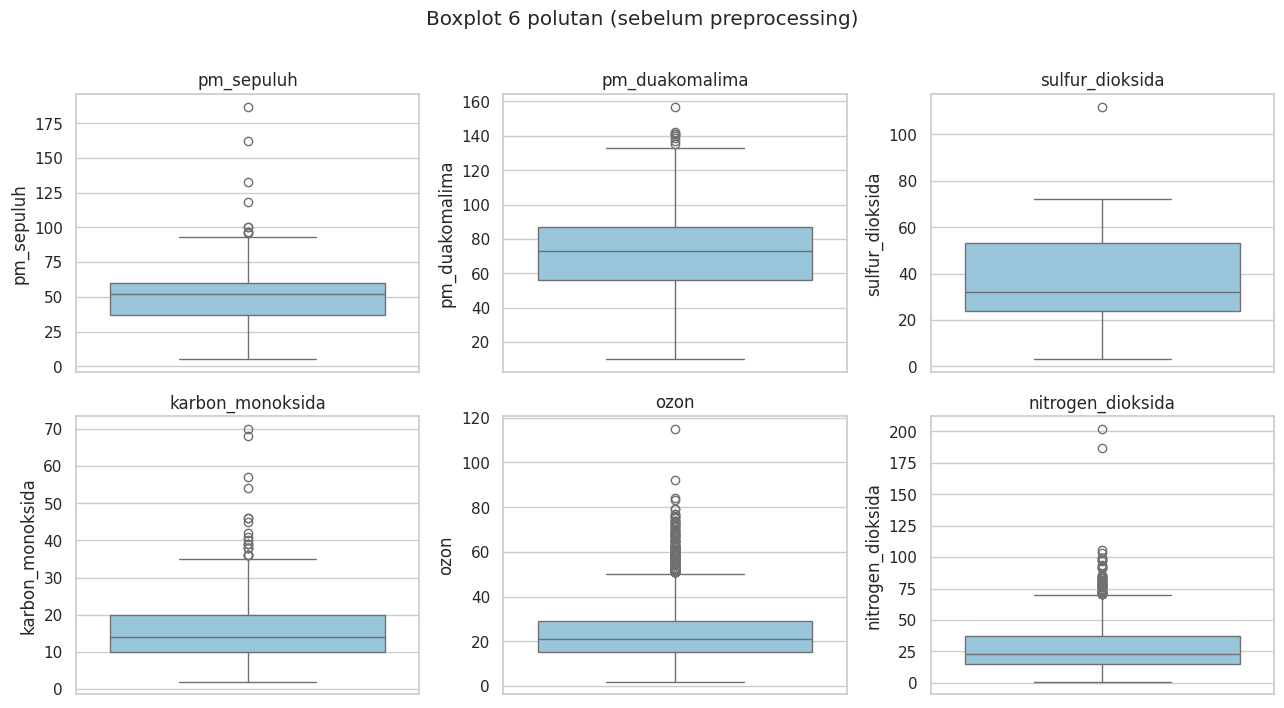

In [7]:
# Boxplot sebelum preprocessing -> melihat outlier
fig, ax = plt.subplots(2,3, figsize=(13,7))
for a,f in zip(ax.ravel(), FITUR):
    sns.boxplot(y=df[f], ax=a, color='#8ecae6')
    a.set_title(f)
plt.suptitle('Boxplot 6 polutan (sebelum preprocessing)', y=1.01)
plt.tight_layout()
plt.savefig('fig_boxplot_sebelum.png', dpi=130, bbox_inches='tight')
plt.show()

In [8]:
# Jumlah outlier per fitur dengan aturan IQR (1.5 x IQR)
rows=[]
for f in FITUR:
    q1,q3 = df[f].quantile([.25,.75])
    i=q3-q1
    lo,hi=q1-1.5*i,q3+1.5*i
    rows.append([f,q1,q3,lo,hi,int(((df[f]<lo)|(df[f]>hi)).sum())])
pd.DataFrame(rows, columns=['fitur','Q1','Q3','batas_bawah','batas_atas','jumlah_outlier']).round(2)

,fitur,Q1,Q3,batas_bawah,batas_atas,jumlah_outlier
0,pm_sepuluh,37.0,60.0,2.5,94.5,9
1,pm_duakomalima,56.0,87.0,9.5,133.5,9
2,sulfur_dioksida,24.0,53.0,-19.5,96.5,1
3,karbon_monoksida,10.0,20.0,-5.0,35.0,20
4,ozon,15.0,29.0,-6.0,50.0,169
5,nitrogen_dioksida,15.0,37.0,-18.0,70.0,60


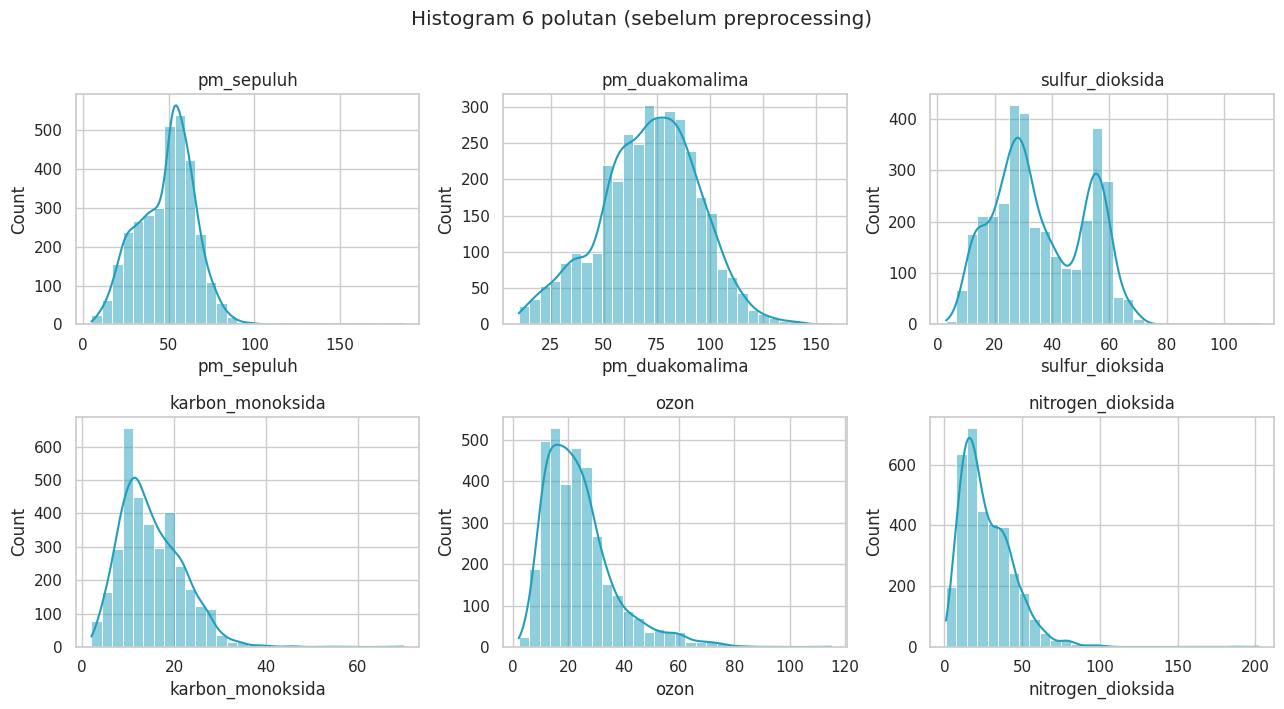

In [9]:
fig, ax = plt.subplots(2,3, figsize=(13,7))
for a,f in zip(ax.ravel(), FITUR):
    sns.histplot(df[f].dropna(), bins=30, kde=True, ax=a, color='#219ebc')
    a.set_title(f)
plt.suptitle('Histogram 6 polutan (sebelum preprocessing)', y=1.01)
plt.tight_layout()
plt.savefig('fig_hist_sebelum.png', dpi=130, bbox_inches='tight')
plt.show()

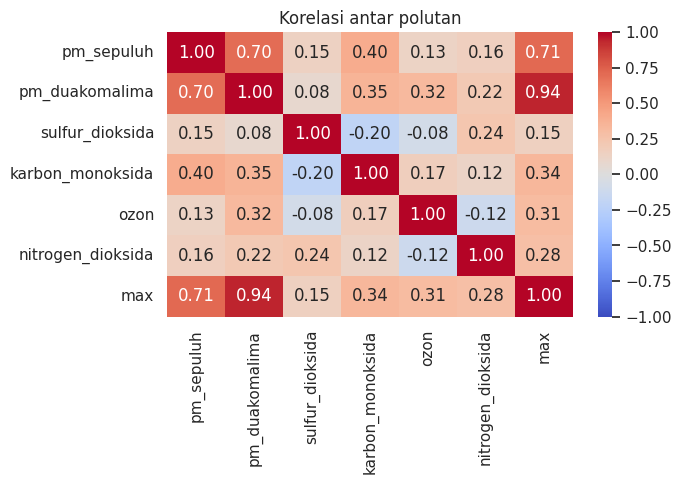

In [10]:
plt.figure(figsize=(7,5))
sns.heatmap(df[FITUR+['max']].corr(), annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1)
plt.title('Korelasi antar polutan')
plt.tight_layout()
plt.savefig('fig_korelasi.png', dpi=130)
plt.show()

In [11]:
# Rata-rata tiap polutan per kategori -> melihat apakah fitur bisa membedakan kelas
df.groupby('kategori')[FITUR].mean().round(1)

,pm_sepuluh,pm_duakomalima,sulfur_dioksida,karbon_monoksida,ozon,nitrogen_dioksida
kategori,,,,,,
BAIK,28.3,35.7,25.9,10.8,18.1,15.3
SANGAT TIDAK SEHAT,43.0,55.0,51.0,10.0,20.0,202.0
SEDANG,49.7,72.2,37.6,15.3,23.8,28.6
TIDAK SEHAT,67.5,109.6,36.4,18.7,31.0,30.6


## 3. Data Preprocessing
1. Samakan nama stasiun (13 variasi menjadi 5 stasiun).
2. Ubah penanda kosong menjadi NaN.
3. Buang baris tanpa label kategori.
4. Gabung kelas SANGAT TIDAK SEHAT (1 baris) ke TIDAK SEHAT.
5. Buang `max` dan `parameter_pencemar_kritis` karena menyebabkan kebocoran data.
6. Split train/test 80:20 (stratified), statistik hanya dari data latih.
7. Imputasi missing value dengan median.
8. Capping outlier dengan batas IQR.
9. Normalisasi Min-Max, karena KNN berbasis jarak.

In [12]:
d = df.copy()
d['stasiun'] = d['stasiun'].str.replace(r'\s+',' ',regex=True).str.strip()
def norm_stasiun(s):
    if 'BUN' in s: return 'DKI1 Bundaran HI'
    if 'KELAPA' in s: return 'DKI2 Kelapa Gading'
    if 'JAGAKARSA' in s: return 'DKI3 Jagakarsa'
    if 'LUBANG' in s: return 'DKI4 Lubang Buaya'
    return 'DKI5 Kebon Jeruk'
d['stasiun'] = d['stasiun'].apply(norm_stasiun)
print(d.stasiun.value_counts())

n0=len(d)
d = d.dropna(subset=['kategori'])
print('Baris dibuang karena tanpa label:', n0-len(d))
d['kategori'] = d['kategori'].replace('SANGAT TIDAK SEHAT','TIDAK SEHAT')
d = d.drop(columns=['max','parameter_pencemar_kritis'])
print('Ukuran setelah pembersihan awal:', d.shape)
print(d.kategori.value_counts())

stasiun
DKI5 Kebon Jeruk      701
DKI3 Jagakarsa        700
DKI1 Bundaran HI      700
DKI2 Kelapa Gading    700
DKI4 Lubang Buaya     700
Name: count, dtype: int64
Baris dibuang karena tanpa label: 21
Ukuran setelah pembersihan awal: (3480, 11)
kategori
SEDANG         2694
BAIK            444
TIDAK SEHAT     342
Name: count, dtype: int64


In [13]:
X = d[FITUR]
y = d['kategori']
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
print('Latih:', X_tr.shape, ' Uji:', X_te.shape)
print('Missing di data latih:\n', X_tr.isna().sum().to_dict())

Latih: (2784, 6)  Uji: (696, 6)
Missing di data latih:
 {'pm_sepuluh': 189, 'pm_duakomalima': 34, 'sulfur_dioksida': 30, 'karbon_monoksida': 26, 'ozon': 22, 'nitrogen_dioksida': 35}


In [14]:
# 7. Imputasi median (dari data latih)
med = X_tr.median()
X_tr = X_tr.fillna(med)
X_te = X_te.fillna(med)

# 8. Capping outlier dengan batas IQR (dari data latih)
q1, q3 = X_tr.quantile(.25), X_tr.quantile(.75)
iqr = q3-q1
lo, hi = q1-1.5*iqr, q3+1.5*iqr
print('Outlier data latih sebelum capping:', ((X_tr<lo)|(X_tr>hi)).sum().to_dict())
X_tr = X_tr.clip(lo, hi, axis=1)
X_te = X_te.clip(lo, hi, axis=1)

# 9. Normalisasi Min-Max
sc = MinMaxScaler().fit(X_tr)
X_tr_s = pd.DataFrame(sc.transform(X_tr), columns=FITUR, index=X_tr.index)
X_te_s = pd.DataFrame(sc.transform(X_te), columns=FITUR, index=X_te.index)
print('Missing tersisa:', int(X_tr_s.isna().sum().sum()+X_te_s.isna().sum().sum()))
X_tr_s.describe().T.round(3)

Outlier data latih sebelum capping: {'pm_sepuluh': 13, 'pm_duakomalima': 9, 'sulfur_dioksida': 1, 'karbon_monoksida': 34, 'ozon': 140, 'nitrogen_dioksida': 50}
Missing tersisa: 0


,count,mean,std,min,25%,50%,75%,max
pm_sepuluh,2784.0,0.505,0.187,0.0,0.375,0.542,0.625,1.0
pm_duakomalima,2784.0,0.497,0.187,0.0,0.372,0.510,0.623,1.0
sulfur_dioksida,2784.0,0.361,0.173,0.0,0.229,0.317,0.538,1.0
karbon_monoksida,2784.0,0.428,0.213,0.0,0.262,0.393,0.557,1.0
ozon,2784.0,0.446,0.233,0.0,0.271,0.396,0.562,1.0
nitrogen_dioksida,2784.0,0.375,0.223,0.0,0.203,0.319,0.522,1.0


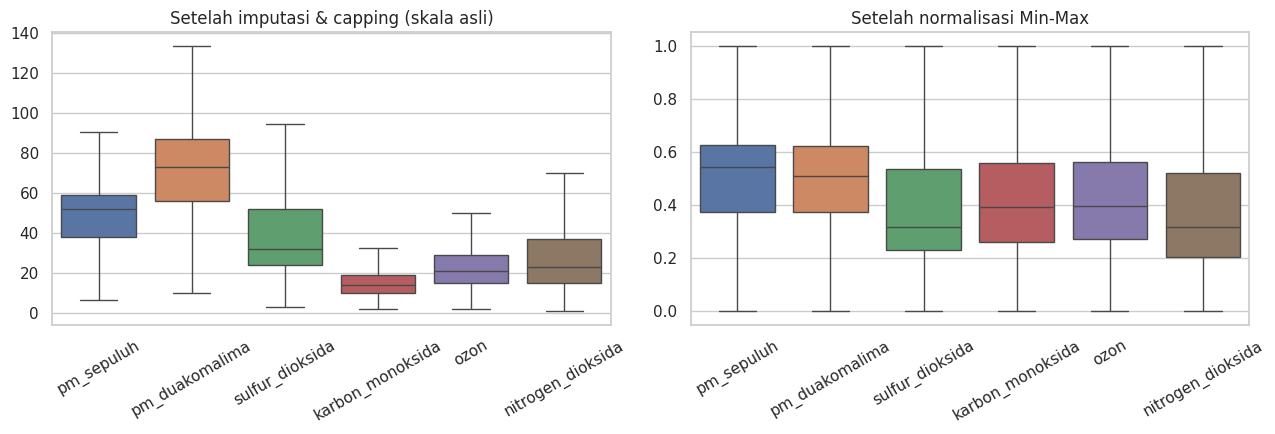

In [15]:
fig, ax = plt.subplots(1,2, figsize=(13,4.5))
sns.boxplot(data=X_tr, ax=ax[0])
ax[0].set_title('Setelah imputasi & capping (skala asli)')
ax[0].tick_params(axis='x', rotation=30)
sns.boxplot(data=X_tr_s, ax=ax[1])
ax[1].set_title('Setelah normalisasi Min-Max')
ax[1].tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.savefig('fig_boxplot_sesudah.png', dpi=130)
plt.show()

## 4. Modeling KNN
Nilai **k** dipilih dengan 5-Fold Cross Validation (metrik macro F1).

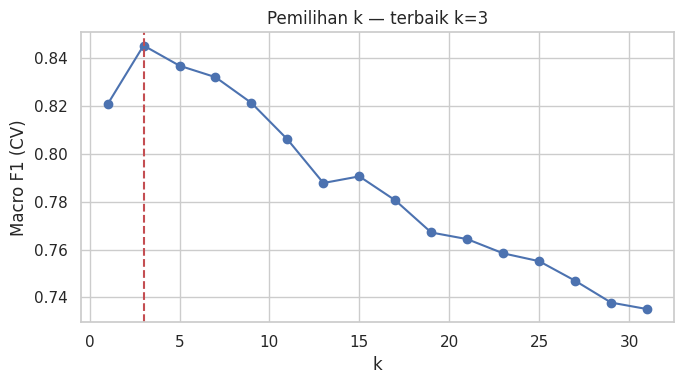

k terbaik = 3 | macro F1 CV = 0.8454


In [16]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
ks = range(1,32,2)
hasil = []
for k in ks:
    s = cross_val_score(KNeighborsClassifier(n_neighbors=k), X_tr_s, y_tr, cv=skf, scoring='f1_macro')
    hasil.append(s.mean())
best_k = list(ks)[int(np.argmax(hasil))]
plt.figure(figsize=(7,4))
plt.plot(list(ks), hasil, marker='o')
plt.axvline(best_k, ls='--', c='r')
plt.xlabel('k')
plt.ylabel('Macro F1 (CV)')
plt.title(f'Pemilihan k — terbaik k={best_k}')
plt.tight_layout()
plt.savefig('fig_pilih_k.png', dpi=130)
plt.show()
print('k terbaik =', best_k, '| macro F1 CV =', round(max(hasil),4))

In [17]:
knn = KNeighborsClassifier(n_neighbors=best_k, metric='euclidean')
knn.fit(X_tr_s, y_tr)
y_pred = knn.predict(X_te_s)
print('Akurasi data uji :', round(accuracy_score(y_te, y_pred),4))
print('Macro F1 data uji:', round(f1_score(y_te, y_pred, average='macro'),4))
base = (y_te==y_tr.mode()[0]).mean()
print('Baseline (selalu tebak kelas mayoritas):', round(base,4))

Akurasi data uji : 0.9224
Macro F1 data uji: 0.8609
Baseline (selalu tebak kelas mayoritas): 0.7744


## 5. Evaluasi

              precision    recall  f1-score   support

        BAIK      0.855     0.798     0.826        89
      SEDANG      0.935     0.967     0.951       539
 TIDAK SEHAT      0.893     0.735     0.806        68

    accuracy                          0.922       696
   macro avg      0.895     0.833     0.861       696
weighted avg      0.921     0.922     0.921       696



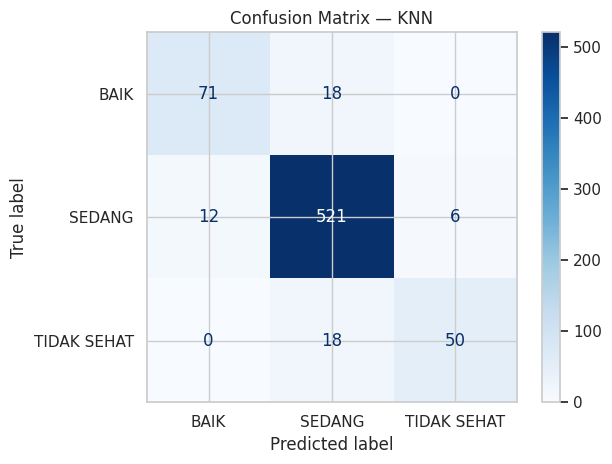

In [18]:
print(classification_report(y_te, y_pred, digits=3))
labels = ['BAIK','SEDANG','TIDAK SEHAT']
cm = confusion_matrix(y_te, y_pred, labels=labels)
ConfusionMatrixDisplay(cm, display_labels=labels).plot(cmap='Blues', values_format='d')
plt.title('Confusion Matrix — KNN')
plt.tight_layout()
plt.savefig('fig_confusion.png', dpi=130)
plt.show()

**Interpretasi:** model lebih baik dari baseline. Kelas TIDAK SEHAT paling sulit ditebak karena datanya sedikit, jadi macro F1 dan recall per kelas ikut diperhatikan.  
**Keterbatasan:** split acak pada data harian berurutan waktu, dan KNN sensitif pada kelas tidak seimbang.

## 6. Verifikasi Hitungan Manual (Soal 2)
Mengulang hitungan manual pada 15 data sampel (imputasi median, capping IQR, Min-Max, KNN k=3). Data uji adalah sampel No 2, 9, dan 12.

In [19]:
sampel = pd.DataFrame({
 'No':range(1,16),
 'pm_sepuluh':[51,35,53,31,74,np.nan,64,30,65,53,13,62,52,36,25],
 'pm_duakomalima':[66,39,83,36,106,24,101,54,97,101,41,102,70,57,50],
 'sulfur_dioksida':[61,28,12,23,56,40,14,23,26,33,13,21,36,np.nan,32],
 'nitrogen_dioksida':[41,13,36,17,18,5,35,14,40,18,8,21,31,12,22],
 'kategori':['SEDANG','BAIK','SEDANG','BAIK','TIDAK SEHAT','BAIK','TIDAK SEHAT','SEDANG','SEDANG','TIDAK SEHAT','BAIK','TIDAK SEHAT','SEDANG','SEDANG','BAIK']})
F4 = ['pm_sepuluh','pm_duakomalima','sulfur_dioksida','nitrogen_dioksida']
s = sampel.copy()
s[F4] = s[F4].fillna(s[F4].median())
def halves(v):
    v=np.sort(v.values)
    n=len(v)
    a=v[:n//2]
    b=v[n//2+(n%2):]
    return np.median(a), np.median(b)
for f in F4:
    q1,q3 = halves(s[f])
    i=q3-q1
    s[f] = s[f].clip(q1-1.5*i, q3+1.5*i)
s[F4] = (s[F4]-s[F4].min())/(s[F4].max()-s[F4].min())
uji = s[s.No.isin([2,9,12])]
latih = s[~s.No.isin([2,9,12])]
m = KNeighborsClassifier(n_neighbors=3).fit(latih[F4], latih.kategori)
hasil = uji[['No','kategori']].assign(prediksi=m.predict(uji[F4]))
print(hasil.to_string(index=False))
print('Akurasi:', (hasil.kategori==hasil.prediksi).mean().round(4))

 No    kategori    prediksi
  2        BAIK      SEDANG
  9      SEDANG      SEDANG
 12 TIDAK SEHAT TIDAK SEHAT
Akurasi: 0.6667


In [20]:
# Menyimpan potongan hasil untuk lembar jawaban
import json
json.dump({'best_k':int(best_k),'acc':float(accuracy_score(y_te,y_pred)),'f1':float(f1_score(y_te,y_pred,average='macro')),'base':float(base)}, open('hasil_model.json','w'))